# Explainable AI for Loan Approval Decisions

**Problem Statement:**
Banks and financial institutions rely on automated Machine Learning models to approve or reject loan applications. However, traditional models act as "black boxes," providing decisions without explaining the underlying reasons to applicants or loan officers.

**Objectives:**
1. Clean, preprocess, and engineer features (combining total `Assets`) from the loan approval dataset.
2. Perform Exploratory Data Analysis (EDA) to uncover key patterns affecting loan approval.
3. Implement and compare three Machine Learning algorithms: Logistic Regression, Random Forest, and XGBoost.
4. Use Explainable AI (SHAP) to interpret global feature importance and individual loan decisions.


In [12]:
import pandas as pd

In [13]:
data=pd.read_csv('loan_approval_dataset.csv')

In [14]:
data.drop(columns=['loan_id'], inplace=True)

C:\Users\nilay\AppData\Local\Temp\ipykernel_9888\2973163609.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop(columns=['loan_id'], inplace=True)


In [15]:
data

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
...,...,...,...,...,...,...,...,...,...,...,...,...
4264,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected
4265,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved
4266,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected
4267,1,Not Graduate,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved


In [16]:
data.columns

Index(['no_of_dependents', 'education', 'self_employed', 'income_annum',
       'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value',
       'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value',
       'loan_status'],
      dtype='str')

In [17]:
data.columns=data.columns.str.strip()

In [18]:
data.columns

Index(['no_of_dependents', 'education', 'self_employed', 'income_annum',
       'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value',
       'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value',
       'loan_status'],
      dtype='str')

In [19]:
data

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
...,...,...,...,...,...,...,...,...,...,...,...,...
4264,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected
4265,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved
4266,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected
4267,1,Not Graduate,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved


In [20]:
data.columns

Index(['no_of_dependents', 'education', 'self_employed', 'income_annum',
       'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value',
       'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value',
       'loan_status'],
      dtype='str')

In [21]:
data['Assets']=data.residential_assets_value + data.commercial_assets_value+data.luxury_assets_value+data.bank_asset_value

In [22]:
data

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status,Assets
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved,50700000
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected,17000000
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected,57700000
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected,52700000
4,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected,55000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4264,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected,7400000
4265,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved,20000000
4266,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected,39000000
4267,1,Not Graduate,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved,28800000


In [23]:
data.drop(columns=['residential_assets_value','commercial_assets_value','luxury_assets_value','bank_asset_value'],inplace=True)

C:\Users\nilay\AppData\Local\Temp\ipykernel_9888\2847005403.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop(columns=['residential_assets_value','commercial_assets_value','luxury_assets_value','bank_asset_value'],inplace=True)


In [24]:
data

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,loan_status,Assets
0,2,Graduate,No,9600000,29900000,12,778,Approved,50700000
1,0,Not Graduate,Yes,4100000,12200000,8,417,Rejected,17000000
2,3,Graduate,No,9100000,29700000,20,506,Rejected,57700000
3,3,Graduate,No,8200000,30700000,8,467,Rejected,52700000
4,5,Not Graduate,Yes,9800000,24200000,20,382,Rejected,55000000
...,...,...,...,...,...,...,...,...,...
4264,5,Graduate,Yes,1000000,2300000,12,317,Rejected,7400000
4265,0,Not Graduate,Yes,3300000,11300000,20,559,Approved,20000000
4266,2,Not Graduate,No,6500000,23900000,18,457,Rejected,39000000
4267,1,Not Graduate,No,4100000,12800000,8,780,Approved,28800000


In [25]:
data

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,loan_status,Assets
0,2,Graduate,No,9600000,29900000,12,778,Approved,50700000
1,0,Not Graduate,Yes,4100000,12200000,8,417,Rejected,17000000
2,3,Graduate,No,9100000,29700000,20,506,Rejected,57700000
3,3,Graduate,No,8200000,30700000,8,467,Rejected,52700000
4,5,Not Graduate,Yes,9800000,24200000,20,382,Rejected,55000000
...,...,...,...,...,...,...,...,...,...
4264,5,Graduate,Yes,1000000,2300000,12,317,Rejected,7400000
4265,0,Not Graduate,Yes,3300000,11300000,20,559,Approved,20000000
4266,2,Not Graduate,No,6500000,23900000,18,457,Rejected,39000000
4267,1,Not Graduate,No,4100000,12800000,8,780,Approved,28800000


In [26]:
data.isnull().sum()

no_of_dependents    0
education           0
self_employed       0
income_annum        0
loan_amount         0
loan_term           0
cibil_score         0
loan_status         0
Assets              0
dtype: int64

In [27]:
data.education.unique()

<StringArray>
['Graduate', 'Not Graduate']
Length: 2, dtype: str

In [28]:
data['education']=data['education'].replace(['Graduate','Not Graduate'],[1,0])

In [29]:
data

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,loan_status,Assets
0,2,1,No,9600000,29900000,12,778,Approved,50700000
1,0,0,Yes,4100000,12200000,8,417,Rejected,17000000
2,3,1,No,9100000,29700000,20,506,Rejected,57700000
3,3,1,No,8200000,30700000,8,467,Rejected,52700000
4,5,0,Yes,9800000,24200000,20,382,Rejected,55000000
...,...,...,...,...,...,...,...,...,...
4264,5,1,Yes,1000000,2300000,12,317,Rejected,7400000
4265,0,0,Yes,3300000,11300000,20,559,Approved,20000000
4266,2,0,No,6500000,23900000,18,457,Rejected,39000000
4267,1,0,No,4100000,12800000,8,780,Approved,28800000


In [30]:
data.self_employed.unique()

<StringArray>
['No', 'Yes']
Length: 2, dtype: str

In [31]:
data.self_employed=data.self_employed.replace(['No','Yes'],[0,1])

In [32]:
data

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,loan_status,Assets
0,2,1,0,9600000,29900000,12,778,Approved,50700000
1,0,0,1,4100000,12200000,8,417,Rejected,17000000
2,3,1,0,9100000,29700000,20,506,Rejected,57700000
3,3,1,0,8200000,30700000,8,467,Rejected,52700000
4,5,0,1,9800000,24200000,20,382,Rejected,55000000
...,...,...,...,...,...,...,...,...,...
4264,5,1,1,1000000,2300000,12,317,Rejected,7400000
4265,0,0,1,3300000,11300000,20,559,Approved,20000000
4266,2,0,0,6500000,23900000,18,457,Rejected,39000000
4267,1,0,0,4100000,12800000,8,780,Approved,28800000


In [33]:
data.loan_status.unique()

<StringArray>
['Approved', 'Rejected']
Length: 2, dtype: str

In [34]:
data.loan_status=data.loan_status.replace(['Approved','Rejected'],[1,0])

In [35]:
data

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,loan_status,Assets
0,2,1,0,9600000,29900000,12,778,1,50700000
1,0,0,1,4100000,12200000,8,417,0,17000000
2,3,1,0,9100000,29700000,20,506,0,57700000
3,3,1,0,8200000,30700000,8,467,0,52700000
4,5,0,1,9800000,24200000,20,382,0,55000000
...,...,...,...,...,...,...,...,...,...
4264,5,1,1,1000000,2300000,12,317,0,7400000
4265,0,0,1,3300000,11300000,20,559,1,20000000
4266,2,0,0,6500000,23900000,18,457,0,39000000
4267,1,0,0,4100000,12800000,8,780,1,28800000


In [36]:
from sklearn.model_selection import train_test_split

In [37]:
input_data=data.drop(columns=['loan_status'])
output_data=data['loan_status']

In [38]:
input_data

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,Assets
0,2,1,0,9600000,29900000,12,778,50700000
1,0,0,1,4100000,12200000,8,417,17000000
2,3,1,0,9100000,29700000,20,506,57700000
3,3,1,0,8200000,30700000,8,467,52700000
4,5,0,1,9800000,24200000,20,382,55000000
...,...,...,...,...,...,...,...,...
4264,5,1,1,1000000,2300000,12,317,7400000
4265,0,0,1,3300000,11300000,20,559,20000000
4266,2,0,0,6500000,23900000,18,457,39000000
4267,1,0,0,4100000,12800000,8,780,28800000


In [39]:
output_data

0       1
1       0
2       0
3       0
4       0
       ..
4264    0
4265    1
4266    0
4267    1
4268    1
Name: loan_status, Length: 4269, dtype: object

In [40]:
x_train,x_test,y_train,y_test=train_test_split(input_data,output_data,test_size=0.2)

In [41]:
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((3415, 8), (854, 8), (3415,), (854,))

In [42]:
from sklearn.preprocessing import StandardScaler

In [43]:
scaler=StandardScaler()

In [44]:
x_train_scaled=scaler.fit_transform(x_train)

In [45]:
x_test_scaled=scaler.transform(x_test)

In [46]:
from sklearn.linear_model import LogisticRegression

In [47]:
model= LogisticRegression()

model.fit(x_train_scaled,y_train)

In [48]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
y_train=le.fit_transform(y_train)
y_test=le.transform(y_test)

In [49]:
model.fit(x_train_scaled,y_train)
accuracy=model.score(x_test_scaled,y_test)
print("model Accuracy:", accuracy)

model Accuracy: 0.9262295081967213


In [50]:
pred_data=pd.DataFrame([[2,1,0,9600000,29900000,12,778,50700000]],columns=['no_of_dependents','education','self_employed','income_annum','loan_amount','loan_term','cibil_score','Assets'])

In [51]:
pred_data=scaler.transform(pred_data)

In [52]:
model.predict(pred_data)

array([1])

In [53]:
import pickle as pk

In [54]:
pk.dump(model, open('model.pkl','wb',))

In [55]:
pk.dump(scaler,open('scaler.pkl','wb'))

In [56]:
!pip install xgboost shap matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable


In [57]:
!pip install

Defaulting to user installation because normal site-packages is not writeable


ERROR: You must give at least one requirement to install (see "pip help install")


In [58]:
%pip install matplotlib seaborn xgboost shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


C:\Users\nilay\AppData\Local\Temp\ipykernel_9888\3800049617.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='loan_status', data=data, palette='Set2', ax=axes[0])
C:\Users\nilay\AppData\Local\Temp\ipykernel_9888\3800049617.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='loan_status', y='cibil_score', data=data, palette='Set1', ax=axes[1])


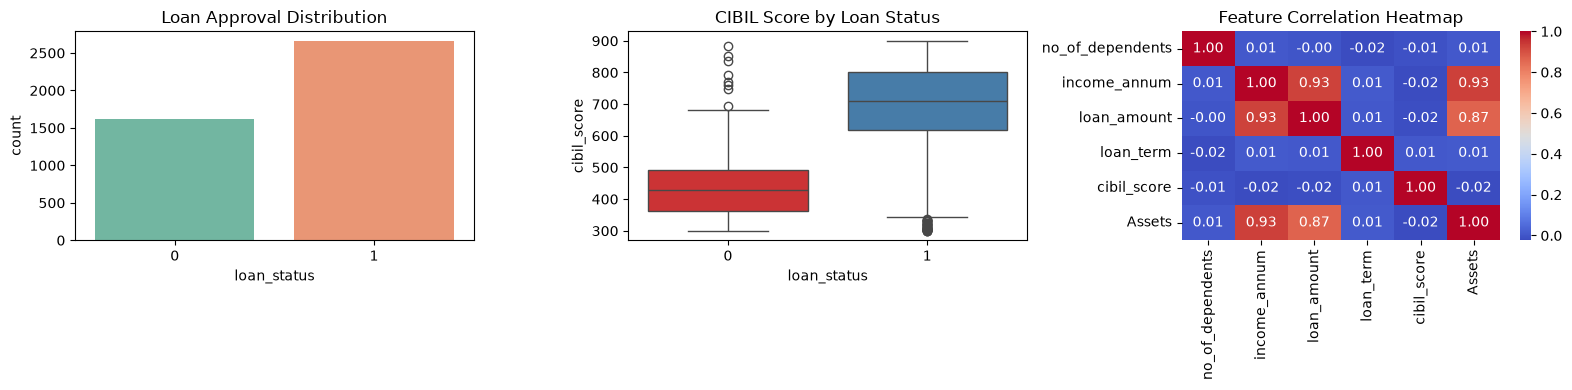

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Graph 1: Count of Approved vs Rejected Loans
sns.countplot(x='loan_status', data=data, palette='Set2', ax=axes[0])
axes[0].set_title('Loan Approval Distribution')

# Graph 2: CIBIL Score vs Loan Status
sns.boxplot(x='loan_status', y='cibil_score', data=data, palette='Set1', ax=axes[1])
axes[1].set_title('CIBIL Score by Loan Status')

# Graph 3: Correlation Heatmap
sns.heatmap(data.corr(numeric_only=True), annot=True, fmt=".2f", cmap='coolwarm', ax=axes[2])
axes[2].set_title('Feature Correlation Heatmap')

plt.tight_layout()
plt.show()

In [63]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Convert to numeric types for XGBoost compatibility
x_tr = x_train.astype(float)
x_te = x_test.astype(float)
y_tr = y_train.astype(int)
y_te = y_test.astype(int)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric='logloss')
}

results = []
for name, clf in models.items():
    clf.fit(x_tr, y_tr)
    y_pred = clf.predict(x_te)
    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_te, y_pred) * 100, 2),
        "Precision (%)": round(precision_score(y_te, y_pred) * 100, 2),
        "Recall (%)": round(recall_score(y_te, y_pred) * 100, 2),
        "F1-Score (%)": round(f1_score(y_te, y_pred) * 100, 2)
    })

comparison_df = pd.DataFrame(results)
display(comparison_df)

,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,Logistic Regression,80.09,80.88,90.56,85.45
1,Random Forest,97.78,97.33,99.27,98.29
2,XGBoost,98.71,98.74,99.27,99.00


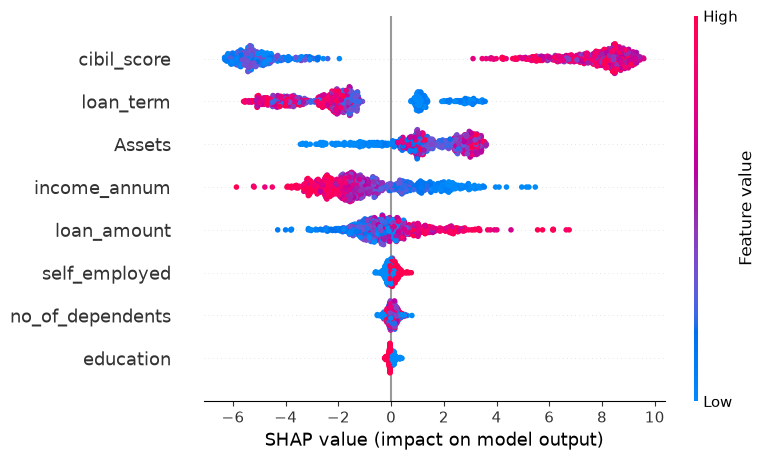

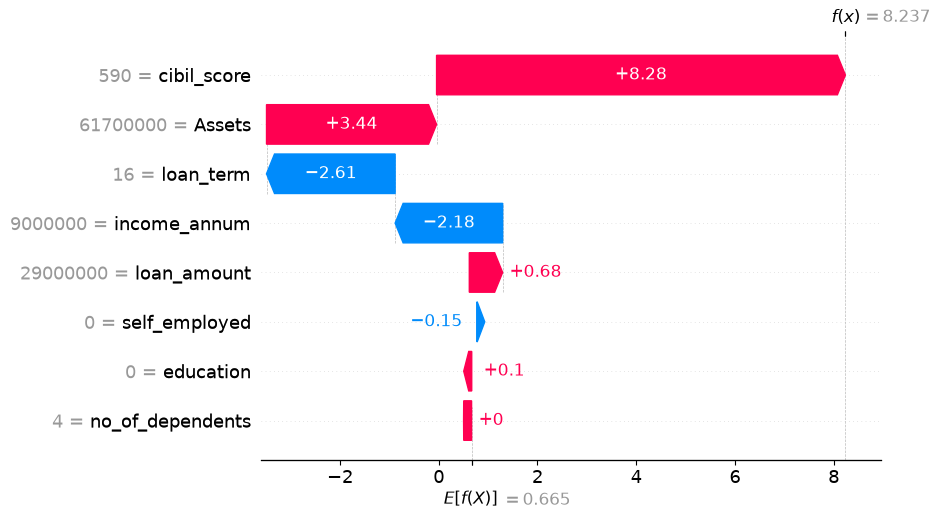

In [61]:
import shap

# Convert all columns to numeric float so SHAP can read them cleanly
x_train_num = x_train.astype(float)
x_test_num = x_test.astype(float)

# Re-fit XGBoost on clean float columns & generate SHAP explanations
xgb_model.fit(x_train_num, y_train)
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(x_test_num)

# 1. Global Feature Importance Plot
shap.summary_plot(shap_values, x_test_num)

# 2. Single Applicant Decision Explanation (Applicant #0)
shap.plots.waterfall(shap_values[0])